In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind

In [2]:
# Load Dataset

file_name = "Sample - Superstore.csv"

try:
    df = pd.read_csv(file_name, encoding="latin1")
except:
    df = pd.read_excel(file_name)

print("\n" + "="*60)
print("DATASET OVERVIEW")
print("="*60)

print("\nShape of Dataset:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
print(df.head())


DATASET OVERVIEW

Shape of Dataset:
(9994, 21)

Columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

First 5 Rows:
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United St

In [3]:
# DATA INFORMATION

print("\n" + "="*60)
print("DATA INFORMATION")
print("="*60)

print(df.info())


DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   flo

In [10]:
# DESCRIPTIVE STATISTICS

print("NUMERICAL STATISTICS")

print(df.describe())

print("CATEGORICAL STATISTICS")

print(df.describe(include="object"))

NUMERICAL STATISTICS
            Row ID   Postal Code         Sales     Quantity     Discount  \
count  9994.000000   9994.000000   9994.000000  9994.000000  9994.000000   
mean   4997.500000  55190.379428    229.858001     3.789574     0.156203   
std    2885.163629  32063.693350    623.245101     2.225110     0.206452   
min       1.000000   1040.000000      0.444000     1.000000     0.000000   
25%    2499.250000  23223.000000     17.280000     2.000000     0.000000   
50%    4997.500000  56430.500000     54.490000     3.000000     0.200000   
75%    7495.750000  90008.000000    209.940000     5.000000     0.200000   
max    9994.000000  99301.000000  22638.480000    14.000000     0.800000   

            Profit  
count  9994.000000  
mean     28.656896  
std     234.260108  
min   -6599.978000  
25%       1.728750  
50%       8.666500  
75%      29.364000  
max    8399.976000  
CATEGORICAL STATISTICS
              Order ID Order Date   Ship Date       Ship Mode Customer ID  \
count

In [9]:
# MISSING VALUES


print("MISSING VALUES")

missing = df.isnull().sum()
print(missing[missing > 0])

MISSING VALUES
Series([], dtype: int64)


In [8]:
# DUPLICATES
print("DUPLICATE RECORDS")
duplicates = df.duplicated().sum()
print("Duplicate Rows:", duplicates)

DUPLICATE RECORDS
Duplicate Rows: 0


In [11]:

# DATA TYPES

print("DATA TYPES")
print(df.dtypes)


DATA TYPES
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


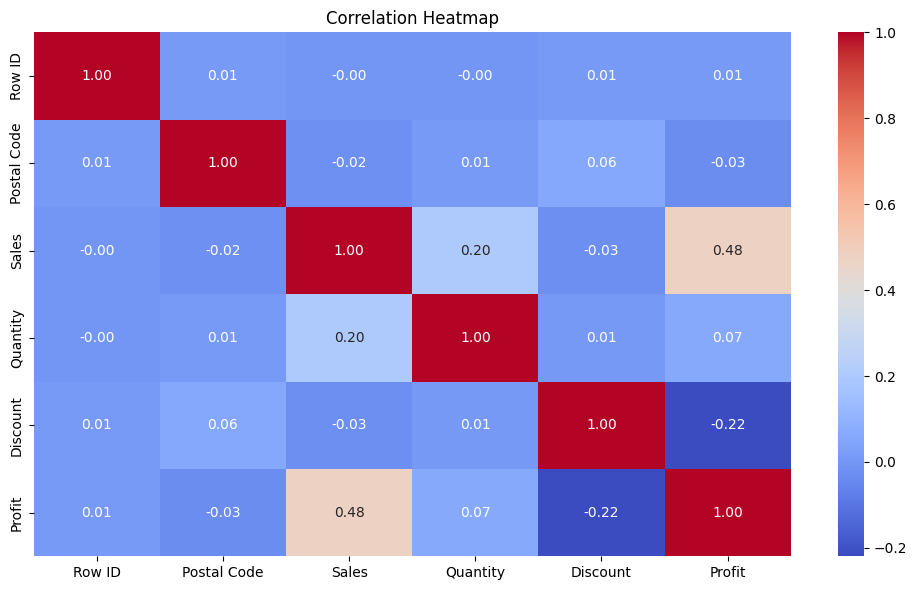

In [12]:
# CORRELATION ANALYSIS

numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] > 1:

    plt.figure(figsize=(10, 6))
    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()


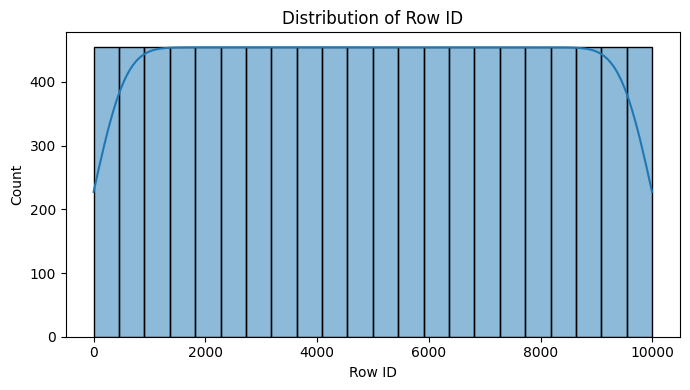

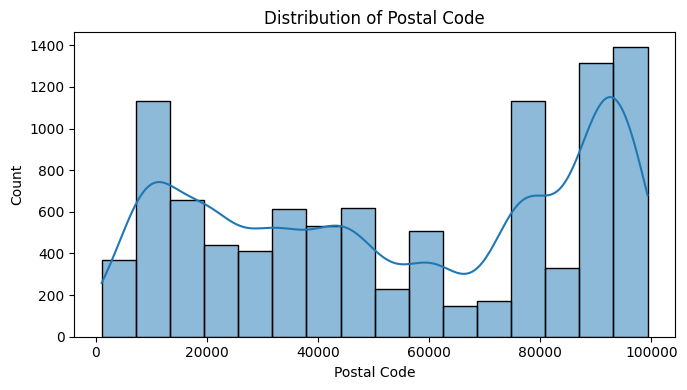

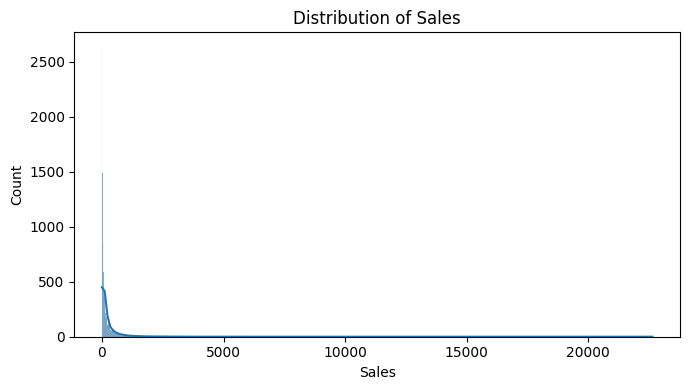

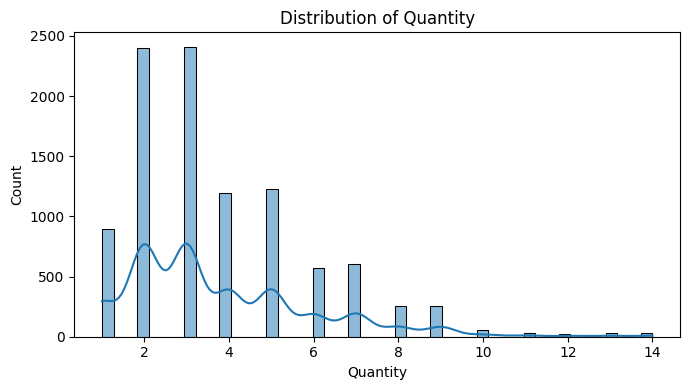

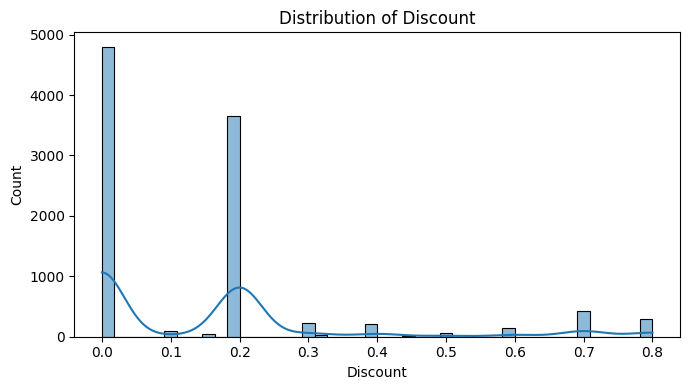

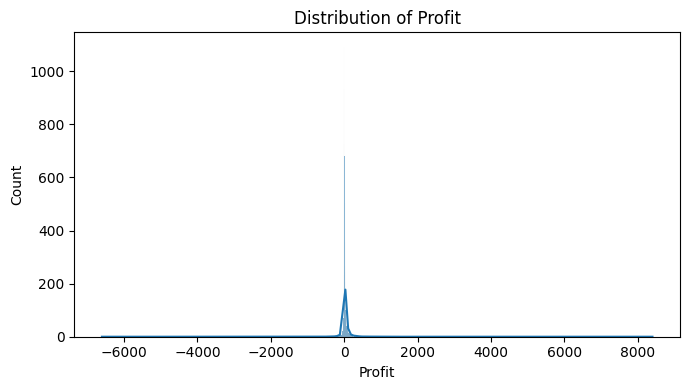

In [13]:
# HISTOGRAMS

for col in numeric_df.columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

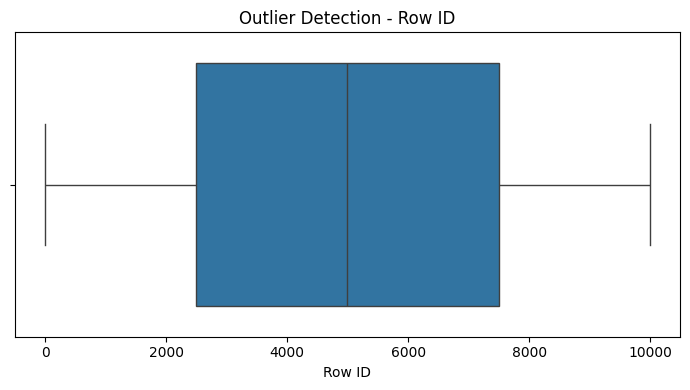

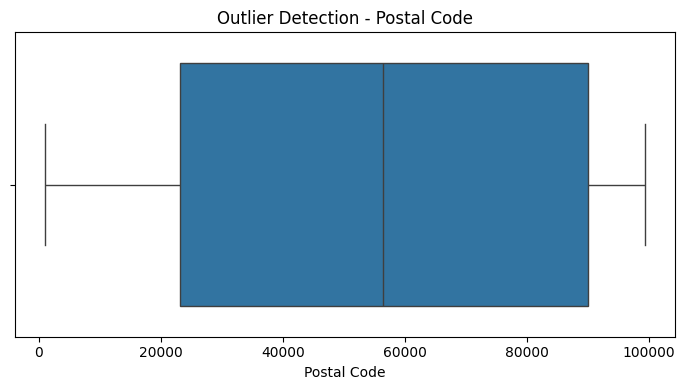

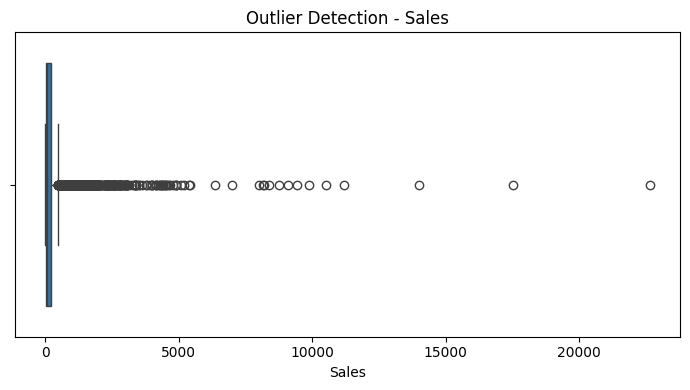

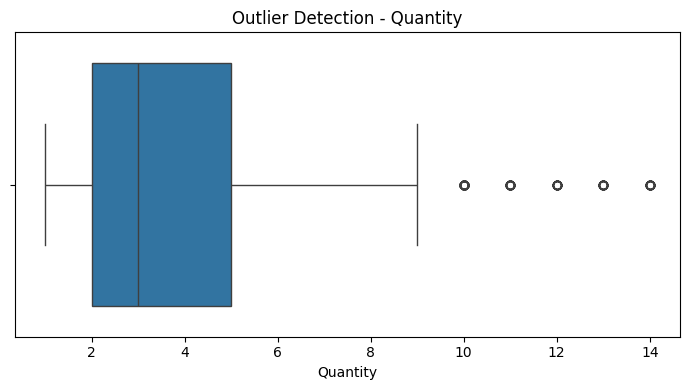

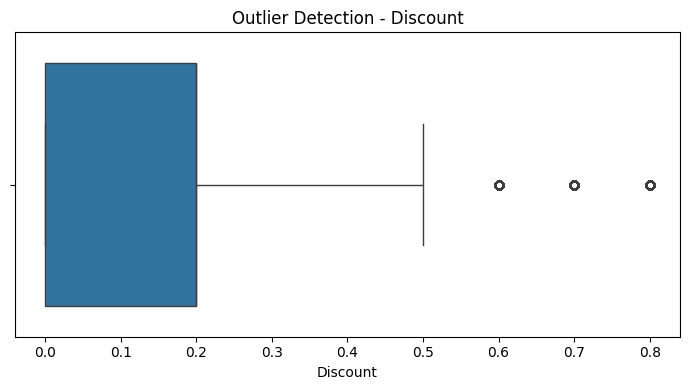

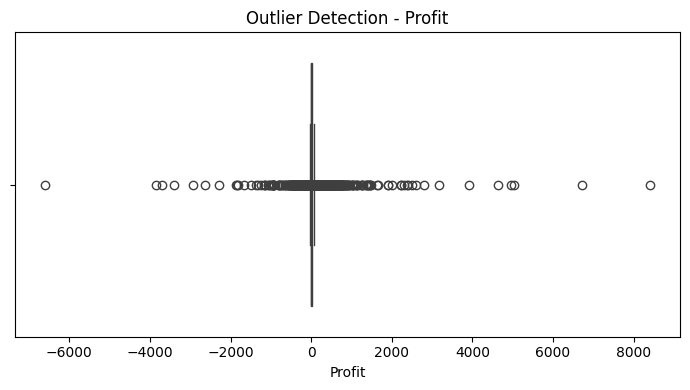

In [14]:

# BOXPLOTS FOR OUTLIERS

for col in numeric_df.columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Outlier Detection - {col}")
    plt.tight_layout()
    plt.show()


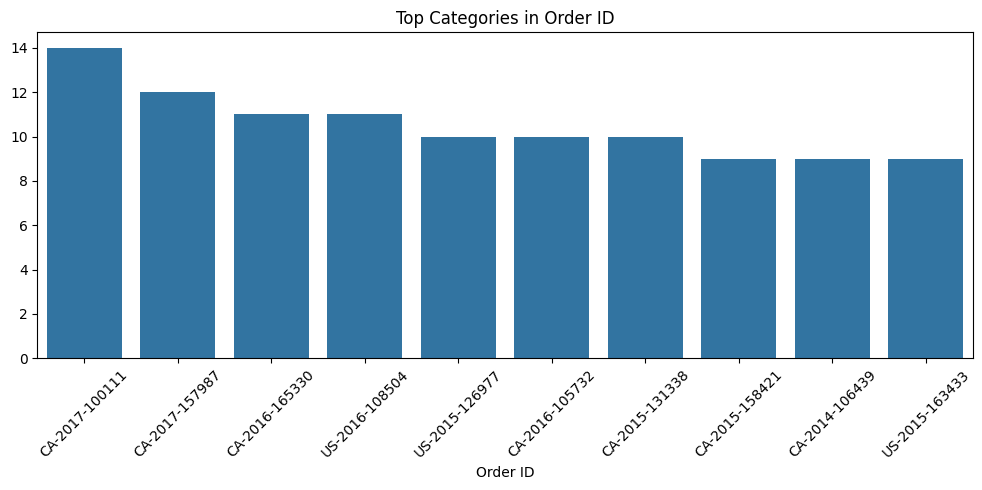

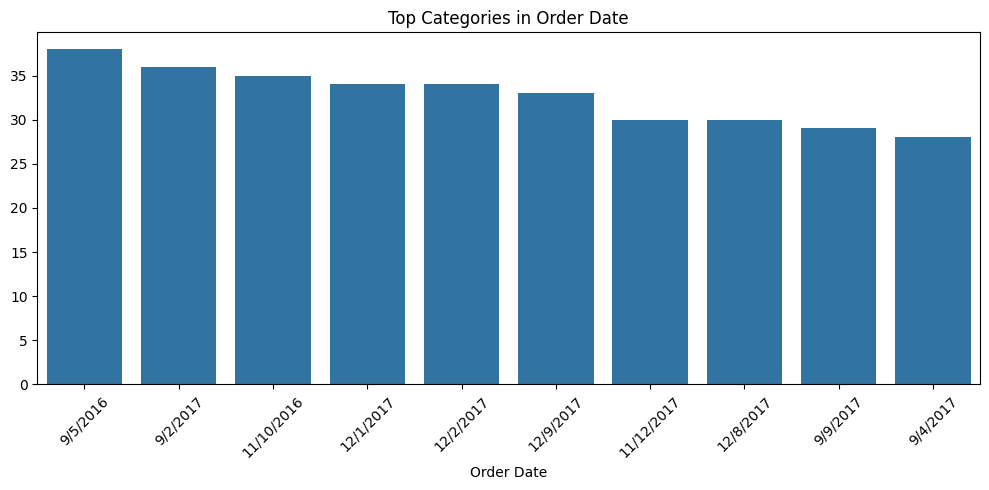

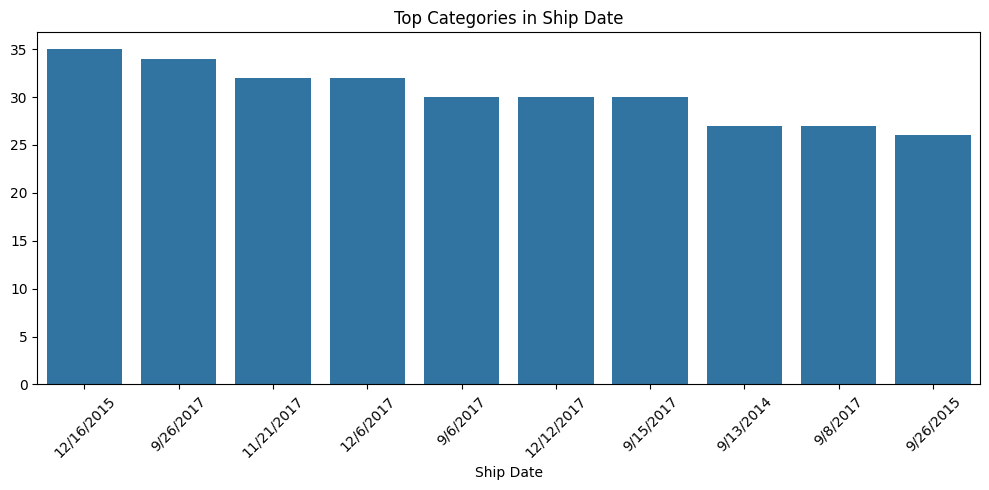

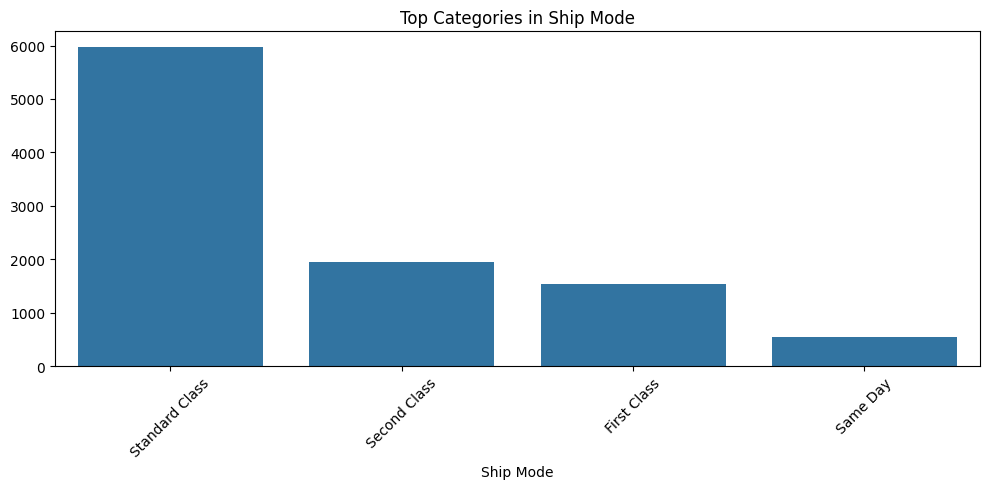

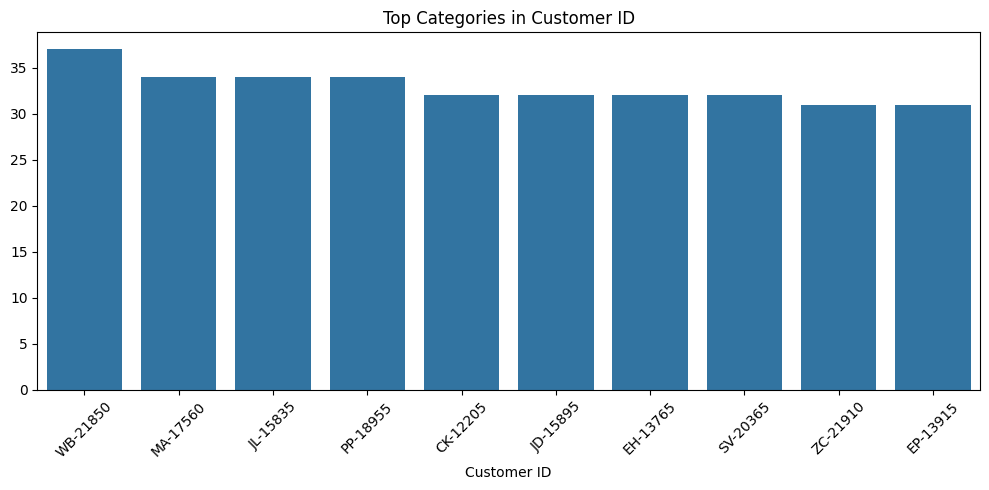

In [15]:
# TOP CATEGORIES

cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols[:5]:
    plt.figure(figsize=(10, 5))

    top_values = df[col].value_counts().head(10)

    sns.barplot(
        x=top_values.index,
        y=top_values.values
    )

    plt.xticks(rotation=45)
    plt.title(f"Top Categories in {col}")
    plt.tight_layout()
    plt.show()


In [16]:
# SALES ANALYSIS

if "Sales" in df.columns:

    print("\n" + "="*60)
    print("SALES INSIGHTS")
    print("="*60)

    print("Total Sales:", round(df["Sales"].sum(), 2))
    print("Average Sales:", round(df["Sales"].mean(), 2))
    print("Maximum Sales:", round(df["Sales"].max(), 2))


SALES INSIGHTS
Total Sales: 2297200.86
Average Sales: 229.86
Maximum Sales: 22638.48


In [18]:
# PROFIT ANALYSIS

if "Profit" in df.columns:

    print("PROFIT INSIGHTS")

    print("Total Profit:", round(df["Profit"].sum(), 2))
    print("Average Profit:", round(df["Profit"].mean(), 2))
    print("Minimum Profit:", round(df["Profit"].min(), 2))

PROFIT INSIGHTS
Total Profit: 286397.02
Average Profit: 28.66
Minimum Profit: -6599.98


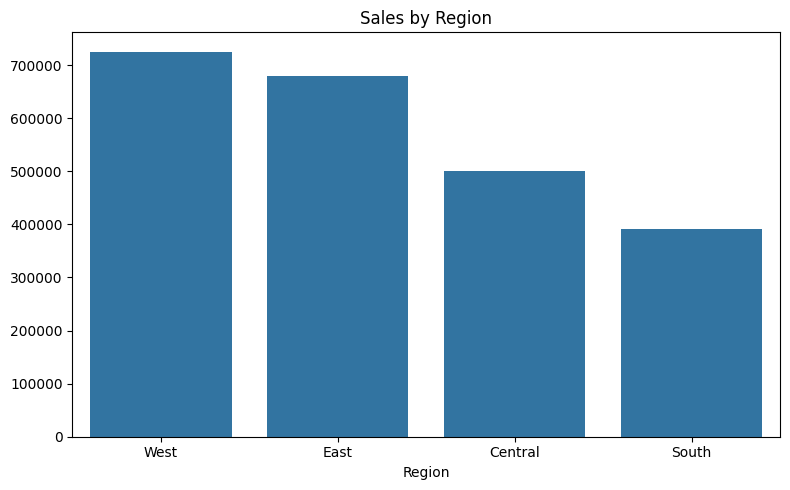

In [19]:
# REGION ANALYSIS

if "Region" in df.columns and "Sales" in df.columns:

    region_sales = (
        df.groupby("Region")["Sales"]
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(8, 5))
    sns.barplot(
        x=region_sales.index,
        y=region_sales.values
    )
    plt.title("Sales by Region")
    plt.tight_layout()
    plt.show()

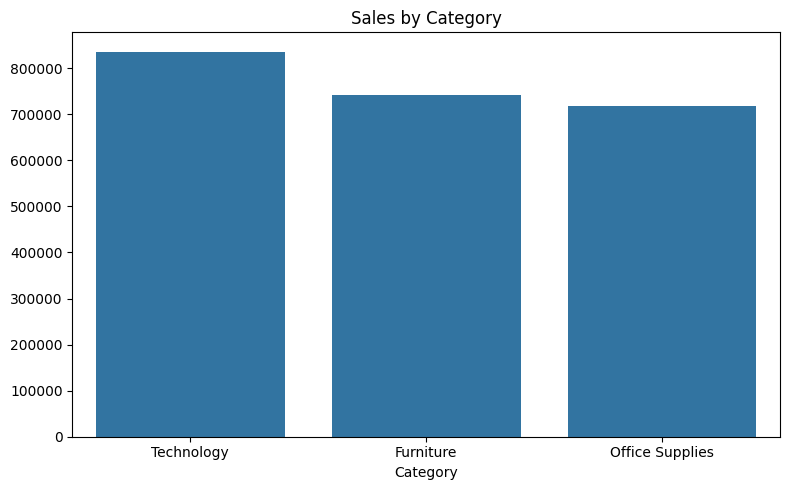

In [21]:
# Category analysis

if "Category" in df.columns and "Sales" in df.columns:

    category_sales = (
        df.groupby("Category")["Sales"]
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(8, 5))
    sns.barplot(
        x=category_sales.index,
        y=category_sales.values
    )
    plt.title("Sales by Category")
    plt.tight_layout()
    plt.show()

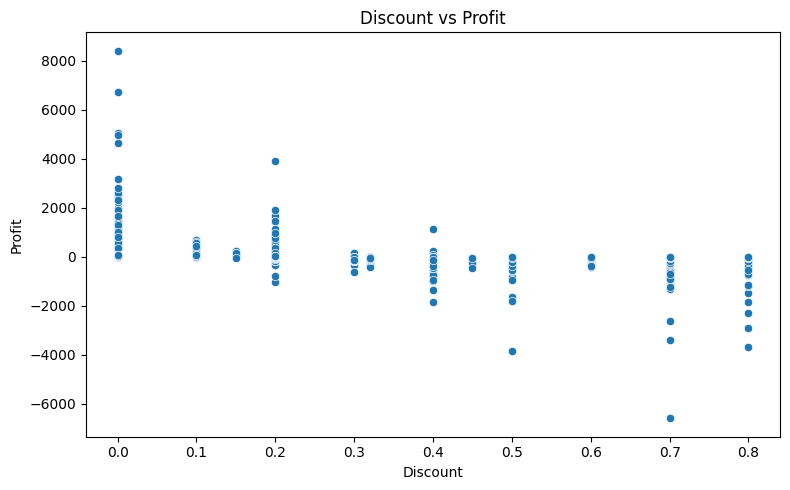

In [22]:
# DISCOUNT VS PROFIT

if "Discount" in df.columns and "Profit" in df.columns:

    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=df,
        x="Discount",
        y="Profit"
    )
    plt.title("Discount vs Profit")
    plt.tight_layout()
    plt.show()


In [26]:
# HYPOTHESIS TEST

if "Profit" in df.columns and "Category" in df.columns:

    categories = df["Category"].unique()

    if len(categories) >= 2:

        group1 = df[df["Category"] == categories[0]]["Profit"]
        group2 = df[df["Category"] == categories[1]]["Profit"]

        t_stat, p_value = ttest_ind(
            group1,
            group2,
            nan_policy="omit"
        )

        print("HYPOTHESIS TEST")

        print(f"T-Statistic : {t_stat:.4f}")
        print(f"P-Value     : {p_value:.4f}")

        if p_value < 0.05:
            print("Reject Null Hypothesis")
        else:
            print("Fail to Reject Null Hypothesis")

HYPOTHESIS TEST
T-Statistic : -2.9169
P-Value     : 0.0035
Reject Null Hypothesis


In [25]:
# OUTLIER COUNT

print("OUTLIER ANALYSIS")

for col in numeric_df.columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(f"{col}: {len(outliers)} outliers")

print("\nEDA COMPLETED SUCCESSFULLY")

OUTLIER ANALYSIS
Row ID: 0 outliers
Postal Code: 0 outliers
Sales: 1167 outliers
Quantity: 170 outliers
Discount: 856 outliers
Profit: 1881 outliers

EDA COMPLETED SUCCESSFULLY
